# GLM-HMM: cross-validation on held-out participants and whole sessions

Figure 4's model selection used pooled cross-validation in which every fold holds out interleaved
trial blocks *within* each session. Each test block is then scored by a model that was trained on the
rest of the same session, so participant-specific behaviour is shared between training and test, and
held-out fit can be overstated. The review asked for the CV to be repeated with whole sessions or
participants held out.

This notebook reads `scripts/shared_glm_hmm/fit_heldout_cv.py`, which refits the Figure 4 model
(`XY__tgt`, identical design matrices) with five folds under two schemes:

* **held-out participant**: both sessions of a patient are in the same test fold; nothing about the
  person is seen in training. This is the strict test.
* **held-out session**: whole sessions held out regardless of participant, so a patient's other session
  may be in training.

Initialisation uses the training sessions only (a one-state GLM per fold, then 6 perturbed restarts per
K, the best training likelihood kept). Held-out sessions are scored with all parameters fixed.

Three questions:

1. **Selection.** Does held-out fit still rise with K, and does the K = 4 choice survive?
2. **Overstatement.** How much better does the interleaved CV make the model look?
3. **Inference.** Does the participant-level quantity used downstream, the occupancy-weighted prior
   effect (`4.20`), come out the same when it is computed from a model that never saw the participant?

Outputs go to the gitignored `outputs/` directory.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from scipy.optimize import linear_sum_assignment

from config import dir_config, main_config
from src.glm_hmm.cv_utils import bernoulli_null_loglik, pooled_bits_per_trial
from src.shared_glm_hmm.fitting import session_arrays

processed_dir = Path(dir_config.data.processed)
OUTPUT_DIR = (Path.cwd().parent / "outputs").resolve()
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0]))

SELECTED_MODEL = main_config.GLM_HMM.final_model
heldout = pickle.load(open(OUTPUT_DIR / "glm_hmm_heldout_cv" / "heldout_cv.pkl", "rb"))
interleaved = pickle.load(open(processed_dir / "shared_glm_hmm" / SELECTED_MODEL / "all_subjects.pkl", "rb"))
final = pickle.load(open(processed_dir / "shared_glm_hmm" / SELECTED_MODEL / "all_subjects_final.pkl", "rb"))
assert heldout["config_name"] == SELECTED_MODEL and list(heldout["sessions"]) == list(interleaved["data"])

scores = heldout["scores"]
sess_md = heldout["session_metadata"].set_index("session_id")
features = interleaved["config"]["model_features"]
COLOUR, STIMULUS = features.index("color"), features.index("stimulus")
BEST_K = final["best_k"]
print(f"model {SELECTED_MODEL}, reported K = {BEST_K}, {len(heldout['sessions'])} sessions, "
      f"{sess_md['subject_id'].nunique()} participants")
print(scores.groupby(["scheme", "n_states"]).size().unstack())

model XY__tgt, reported K = 4, 100 sessions, 59 participants
n_states       1    2    3    4    5    6
scheme                                   
participant  100  100  100  100  100  100
session      100  100  100  100  100  100


## Part 1. Held-out fit by number of states

Scored exactly as Figure 4: bits per trial above a Bernoulli null that predicts each session's own
right-choice rate, with the spread across folds as the error bar and the same 1-SEM parsimony rule.
The interleaved curve is recomputed from the saved Figure 4 CV.

In [3]:
null_ll = {}
for session, frame in interleaved["data"].items():
    ll, n = bernoulli_null_loglik({session: frame})
    null_ll[session] = ll
scores["null_ll"] = scores["session_id"].map(null_ll)


def scheme_curve(block):
    """Pooled bits/trial per K and the fold spread, matching pooled_bits_per_trial."""
    rows = []
    for k, by_k in block.groupby("n_states"):
        folds = by_k.groupby("fold")[["test_ll", "null_ll", "n_valid"]].sum()
        bits_fold = (folds["test_ll"] - folds["null_ll"]) / (folds["n_valid"] * np.log(2))
        total = folds.sum()
        rows.append({"K": k, "bits": (total["test_ll"] - total["null_ll"]) / (total["n_valid"] * np.log(2)),
                     "sem": bits_fold.std(ddof=0) / np.sqrt(len(bits_fold))})
    return pd.DataFrame(rows).set_index("K")


def parsimonious_k(curve):
    best = curve["bits"].idxmax()
    cutoff = curve.loc[best, "bits"] - curve.loc[best, "sem"]
    return int(next(k for k in curve.index if k <= best and curve.loc[k, "bits"] >= cutoff)), int(best)


g = interleaved["group_pooled_cv"]
null_total, n_total = bernoulli_null_loglik(interleaved["data"])
bits, sem = pooled_bits_per_trial(g["test_ll"], g["n_test_trials"], null_total, n_total)
curves = {"interleaved trials (Figure 4)": pd.DataFrame({"bits": bits, "sem": sem}, index=pd.Index(np.asarray(g["state_range"]), name="K")),
          "held-out session": scheme_curve(scores[scores["scheme"] == "session"]),
          "held-out participant": scheme_curve(scores[scores["scheme"] == "participant"])}

selection = pd.DataFrame({name: {"1-SEM K": parsimonious_k(c)[0], "peak K": parsimonious_k(c)[1],
                                 "bits at K=1": c.loc[1, "bits"], f"bits at K={BEST_K}": c.loc[BEST_K, "bits"],
                                 f"gain K=1 to {BEST_K}": c.loc[BEST_K, "bits"] - c.loc[1, "bits"],
                                 "bits at peak": c["bits"].max()} for name, c in curves.items()}).T
comparison = pd.concat({name: c for name, c in curves.items()}, axis=1)
display(comparison.round(4))
selection.round(4)

interleaved trials (Figure 4)         held-out session          \
                           bits     sem             bits     sem   
K                                                                  
1                        0.1981  0.0031           0.1957  0.0174   
2                        0.2162  0.0030           0.2209  0.0177   
3                        0.2229  0.0033           0.2290  0.0180   
4                        0.2268  0.0034           0.2341  0.0181   
5                        0.2283  0.0033           0.2355  0.0185   
6                        0.2291  0.0033           0.2377  0.0182   

  held-out participant          
                  bits     sem  
K                               
1               0.1951  0.0192  
2               0.2198  0.0184  
3               0.2287  0.0176  
4               0.2342  0.0175  
5               0.2377  0.0174  
6               0.2393  0.0177

,1-SEM K,peak K,bits at K=1,bits at K=4,gain K=1 to 4,bits at peak
interleaved trials (Figure 4),4.0,6.0,0.1981,0.2268,0.0287,0.2291
held-out session,2.0,6.0,0.1957,0.2341,0.0385,0.2377
held-out participant,3.0,6.0,0.1951,0.2342,0.0391,0.2393


### Paired per-participant comparison of K

Fold-level error bars treat five folds as the sample. The sharper question for selection is whether
going from K to K + 1 improves held-out fit *for most participants*. Each participant's held-out log
likelihood (summed over their sessions) is compared between adjacent K, under the participant scheme.

In [4]:
part = scores[scores["scheme"] == "participant"]
per_participant = part.pivot_table(index="subject_id", columns="n_states", values="test_ll", aggfunc="sum")
trials = part[part["n_states"] == 1].groupby("subject_id")["n_valid"].sum()

steps = []
for k in per_participant.columns[1:]:
    gain = (per_participant[k] - per_participant[k - 1]) / (trials * np.log(2))   # bits/trial, per participant
    test = stats.wilcoxon(gain)
    steps.append({"step": f"K {k - 1} to {k}", "median gain (bits/trial)": gain.median(), "mean gain": gain.mean(),
                  "participants improved": f"{int((gain > 0).sum())} / {len(gain)}", "Wilcoxon p": test.pvalue})
gain_1_to_best = (per_participant[BEST_K] - per_participant[1]) / (trials * np.log(2))
steps.append({"step": f"K 1 to {BEST_K}", "median gain (bits/trial)": gain_1_to_best.median(), "mean gain": gain_1_to_best.mean(),
              "participants improved": f"{int((gain_1_to_best > 0).sum())} / {len(gain_1_to_best)}",
              "Wilcoxon p": stats.wilcoxon(gain_1_to_best).pvalue})
paired_k = pd.DataFrame(steps).set_index("step")
paired_k.round(4)

,median gain (bits/trial),mean gain,participants improved,Wilcoxon p
step,,,,
K 1 to 2,0.0184,0.0246,45 / 59,0.0000
K 2 to 3,0.0096,0.0096,44 / 59,0.0000
K 3 to 4,0.0029,0.0047,40 / 59,0.0007
K 4 to 5,0.0021,0.0033,40 / 59,0.0014
K 5 to 6,0.0016,0.0017,35 / 59,0.0197
K 1 to 4,0.0320,0.0390,54 / 59,0.0000


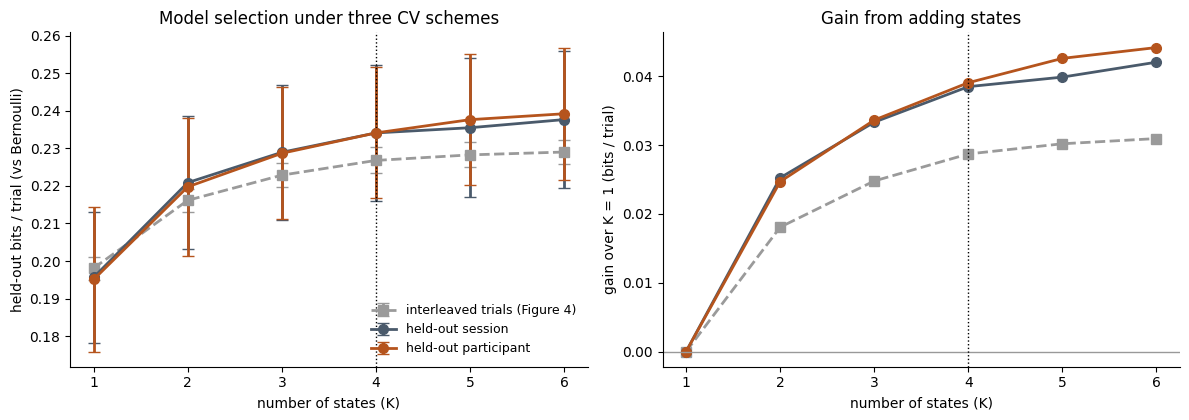

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
styles = {"interleaved trials (Figure 4)": ("#9A9A9A", "s", "--"), "held-out session": ("#4A5A6B", "o", "-"),
          "held-out participant": ("#B5541D", "o", "-")}
ax = axes[0]
for name, c in curves.items():
    color, marker, ls = styles[name]
    ax.errorbar(c.index, c["bits"], yerr=c["sem"], marker=marker, ls=ls, color=color, lw=2, ms=7, capsize=4, label=name)
ax.axvline(BEST_K, color="k", ls=":", lw=1)
ax.set_xlabel("number of states (K)"); ax.set_ylabel("held-out bits / trial (vs Bernoulli)")
ax.set_title("Model selection under three CV schemes", fontsize=12); ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for name, c in curves.items():
    color, marker, ls = styles[name]
    ax.plot(c.index, c["bits"] - c.loc[1, "bits"], marker=marker, ls=ls, color=color, lw=2, ms=7, label=name)
ax.axhline(0, color="0.6", lw=1)
ax.axvline(BEST_K, color="k", ls=":", lw=1)
ax.set_xlabel("number of states (K)"); ax.set_ylabel("gain over K = 1 (bits / trial)")
ax.set_title("Gain from adding states", fontsize=12)
for a in axes:
    a.set_xticks(curves["held-out participant"].index)
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "glm_hmm_heldout_cv.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "glm_hmm_heldout_cv.png", dpi=200, bbox_inches="tight"); plt.show()

## Part 2. Are the states the same when participants are left out?

Each fold's model at the reported K is fitted on about 80% of participants. Its states are matched to the
full-data pooled model (Hungarian assignment on the weights, as in `4.10`) and the weights compared.
If the states are a property of the population rather than of particular individuals, the fold models
should reproduce them.

In [6]:
def align(weights, reference):
    cost = ((weights[:, None, :] - reference[None, :, :]) ** 2).sum(-1)
    _, col = linear_sum_assignment(cost)
    inverse = np.empty_like(col); inverse[col] = np.arange(len(col))
    return inverse


reference = -final["model"]["pooled"].observations.params[:, 0, :]
state_rows = []
for fold in range(heldout["settings"]["k_folds"]):
    model = heldout["fold_models"][("participant", fold, BEST_K)]
    weights = -model.observations.params[:, 0, :]
    aligned = weights[align(weights, reference)]
    for k in range(BEST_K):
        state_rows.append({"fold": fold, "state": k + 1, "colour weight": aligned[k, COLOUR],
                           "stimulus weight": aligned[k, STIMULUS],
                           "r with full-data weights": np.corrcoef(aligned[k], reference[k])[0, 1],
                           "max |difference|": np.abs(aligned[k] - reference[k]).max()})
fold_states = pd.DataFrame(state_rows)
full = pd.DataFrame({"state": np.arange(1, BEST_K + 1), "colour (full data)": reference[:, COLOUR],
                     "stimulus (full data)": reference[:, STIMULUS]}).set_index("state")
state_summary = full.join(fold_states.groupby("state").agg(
    colour_fold_min=("colour weight", "min"), colour_fold_max=("colour weight", "max"),
    stimulus_fold_min=("stimulus weight", "min"), stimulus_fold_max=("stimulus weight", "max"),
    min_r=("r with full-data weights", "min")))
state_summary.round(3)

,colour (full data),stimulus (full data),colour_fold_min,colour_fold_max,stimulus_fold_min,stimulus_fold_max,min_r
state,,,,,,,
1,0.038,3.000,-0.083,0.167,2.856,3.451,0.998
2,0.334,2.956,0.171,0.431,2.766,3.058,0.998
3,0.283,7.900,-0.147,0.535,6.672,8.348,0.997
4,0.169,0.702,0.102,0.204,0.659,0.859,0.980


## Part 3. The participant-level HMM measure, out of sample

`4.20` computes, per session, the occupancy-weighted prior effect $\sum_k \text{occupancy}_k \, w_{\text{colour},k}$
from session models warm-started at the full-data pooled model, which was trained on that same
session. Here the same quantity is computed two ways from models that never saw the participant:

* **held-out refit**: the session model warm-started at the fold's pooled model instead, then refitted
  on the session exactly as in `4.20` (2,500 EM iterations);
* **fixed fold model**: no refit at all; the fold's pooled model's weights, with the session's
  posterior state occupancy. Only occupancy can vary between sessions here, so this is the strictest
  version.

Each is compared with the published measure, and the `4.20` paired tests are repeated on it.

In [7]:
observations, inputs, masks = session_arrays(interleaved)
index_of = {s: i for i, s in enumerate(heldout["sessions"])}
folds = heldout["folds"]["participant"]


def occupancy_effect(model, i):
    weights = -model.observations.params[:, 0, :]
    posterior = model.expected_states(data=observations[i], input=inputs[i], mask=masks[i])[0]
    occupancy = posterior[masks[i][:, 0]].mean(0)
    return float(occupancy @ weights[:, COLOUR])


rows = []
for session, i in index_of.items():
    rows.append({"session_id": session,
                 "heldout_refit": occupancy_effect(heldout["heldout_session_models"][session], i),
                 "fixed_fold_model": occupancy_effect(heldout["fold_models"][("participant", folds[session], BEST_K)], i)})
oos = pd.DataFrame(rows).set_index("session_id")
published = pd.read_csv(OUTPUT_DIR / "hmm_occupancy_weighted.csv").set_index("session_id")
oos = oos.join(published[["prior_effect", "subject_id", "is_pd", "subtype", "medication", "group"]]).rename(columns={"prior_effect": "published"})

agreement = []
for variant in ["heldout_refit", "fixed_fold_model"]:
    r = stats.pearsonr(oos["published"], oos[variant])
    rho = stats.spearmanr(oos["published"], oos[variant])
    agreement.append({"variant": variant, "level": "session", "n": len(oos), "pearson r": r.statistic,
                      "spearman rho": rho.statistic, "mean difference": (oos[variant] - oos["published"]).mean()})
print(f"{len(oos)} sessions")

100 sessions


In [8]:
def paired_changes(frame, column):
    wide = (frame[frame["is_pd"] == 1].pivot_table(index=["subject_id", "subtype"], columns="medication", values=column)
            .dropna().reset_index())
    wide["change"] = wide["on"] - wide["off"]
    return wide.set_index("subject_id")


changes = {v: paired_changes(oos, v) for v in ["published", "heldout_refit", "fixed_fold_model"]}
for variant in ["heldout_refit", "fixed_fold_model"]:
    a, b = changes["published"]["change"], changes[variant]["change"].reindex(changes["published"].index)
    agreement.append({"variant": variant, "level": "PD OFF to ON change", "n": len(a),
                      "pearson r": stats.pearsonr(a, b).statistic, "spearman rho": stats.spearmanr(a, b).statistic,
                      "mean difference": (b - a).mean()})
agreement = pd.DataFrame(agreement).set_index(["variant", "level"])
agreement.round(3)

,,n,pearson r,spearman rho,mean difference
variant,level,,,,
heldout_refit,session,100,0.997,0.996,0.009
fixed_fold_model,session,100,-0.220,-0.132,-0.046
heldout_refit,PD OFF to ON change,22,0.999,0.999,-0.003
fixed_fold_model,PD OFF to ON change,22,-0.287,-0.230,-0.183


In [9]:
def group_tests(frame, column):
    """The 4.20 tests: paired OFF vs ON within subtype, and tremor vs bradykinesia change."""
    wide = paired_changes(frame, column)
    out = []
    for subtype in ["tremor", "bradykinetic"]:
        block = wide[wide["subtype"] == subtype]
        out.append({"test": f"{subtype}: OFF vs ON (paired)", "n": len(block), "effect": block["change"].mean(),
                    "dz": block["change"].mean() / block["change"].std(), "p": stats.wilcoxon(block["off"], block["on"]).pvalue})
    a = wide.loc[wide["subtype"] == "tremor", "change"]
    b = wide.loc[wide["subtype"] == "bradykinetic", "change"]
    out.append({"test": "tremor vs brady medication effect", "n": f"{len(a)} v {len(b)}", "effect": a.mean() - b.mean(),
                "dz": np.nan, "p": stats.mannwhitneyu(a, b).pvalue})
    return pd.DataFrame(out).set_index("test")


group_comparison = pd.concat({v: group_tests(oos, v) for v in ["published", "heldout_refit", "fixed_fold_model"]}, axis=1)
group_comparison.round(4)

published                          \
                                          n  effect      dz       p   
test                                                                  
tremor: OFF vs ON (paired)               11  0.5868  0.5718  0.1016   
bradykinetic: OFF vs ON (paired)         10  0.0131  0.0154  1.0000   
tremor vs brady medication effect   11 v 10  0.5737     NaN  0.2453   

                                  heldout_refit                         \
                                              n  effect     dz       p   
test                                                                     
tremor: OFF vs ON (paired)                   11  0.5802  0.578  0.1016   
bradykinetic: OFF vs ON (paired)             10  0.0106  0.012  0.9219   
tremor vs brady medication effect       11 v 10  0.5696    NaN  0.2178   

                                  fixed_fold_model                          
                                                 n  effect      dz       p  
test                                                                        
tremor: OFF vs ON (paired)                      11  0.0109  0.0808  0.5195  
bradykinetic: OFF vs ON (paired)                10  0.0560  0.4975  0.1309  
tremor vs brady medication effect          11 v 10 -0.0451     NaN  0.6985

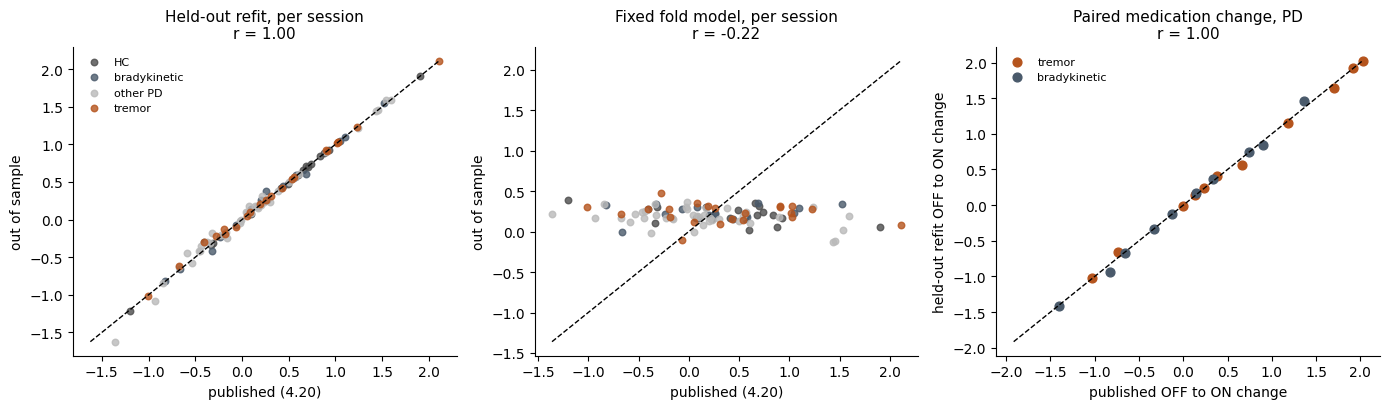

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
colors = {"HC": "#4C4C4C", "tremor": "#B5541D", "bradykinetic": "#4A5A6B"}
for ax, variant, title in [(axes[0], "heldout_refit", "Held-out refit, per session"),
                           (axes[1], "fixed_fold_model", "Fixed fold model, per session")]:
    for label, block in oos.groupby(oos["subtype"].where(oos["subtype"].isin(colors), "other PD")):
        ax.scatter(block["published"], block[variant], s=22, alpha=0.8, color=colors.get(label, "#B9B9B9"), label=label)
    lims = [min(oos["published"].min(), oos[variant].min()), max(oos["published"].max(), oos[variant].max())]
    ax.plot(lims, lims, color="k", lw=1, ls="--")
    ax.set_xlabel("published (4.20)"); ax.set_ylabel("out of sample")
    ax.set_title(f"{title}\nr = {agreement.loc[(variant, 'session'), 'pearson r']:.2f}", fontsize=11)
axes[0].legend(frameon=False, fontsize=8)

ax = axes[2]
pub, ref = changes["published"], changes["heldout_refit"].reindex(changes["published"].index)
for subtype in ["tremor", "bradykinetic"]:
    m = pub["subtype"] == subtype
    ax.scatter(pub.loc[m, "change"], ref.loc[m, "change"], s=40, color=colors[subtype], label=subtype)
lims = [min(pub["change"].min(), ref["change"].min()), max(pub["change"].max(), ref["change"].max())]
ax.plot(lims, lims, color="k", lw=1, ls="--")
ax.set_xlabel("published OFF to ON change"); ax.set_ylabel("held-out refit OFF to ON change")
ax.set_title(f"Paired medication change, PD\nr = {agreement.loc[('heldout_refit', 'PD OFF to ON change'), 'pearson r']:.2f}", fontsize=11)
ax.legend(frameon=False, fontsize=8)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "glm_hmm_heldout_inference.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "glm_hmm_heldout_inference.png", dpi=200, bbox_inches="tight"); plt.show()

In [11]:
comparison.to_csv(OUTPUT_DIR / "glm_hmm_heldout_cv_curves.csv")
selection.to_csv(OUTPUT_DIR / "glm_hmm_heldout_cv_selection.csv")
paired_k.to_csv(OUTPUT_DIR / "glm_hmm_heldout_cv_paired_k.csv")
state_summary.to_csv(OUTPUT_DIR / "glm_hmm_heldout_state_stability.csv")
oos.to_csv(OUTPUT_DIR / "glm_hmm_heldout_occupancy_weighted.csv")
agreement.to_csv(OUTPUT_DIR / "glm_hmm_heldout_agreement.csv")
group_comparison.to_csv(OUTPUT_DIR / "glm_hmm_heldout_group_tests.csv")
print("saved held-out CV tables and figures")

saved held-out CV tables and figures
